# Universidad del Gran Rosario - UGR
# Ingeniería del Software
## Trabajo Práctico
### Introducción a las metodologías y procesos de Ciencia de Datos
#### Carrera: Licenciatura en Ciencia de Datos - CCC
#### Docentes: Ing. Ignacio Sanseovich - Lic. Briant Gauna

#### Grupo 14
#### Estudiantes:
* Agustín Alsop
* Marcos Gomez Hollger
* Alexia Aubone
* Germán Ponce
* Agustin Serra Rivero

### Estudio de Caso
Este trabajo se basa en la aplicación de una metodología de Minería de Datos y su implementación en una solución de software.

Lo que se espera es que el grupo desarrolle:
* Una metodología clara de cómo se procesarán los datos y su resultado e interpretación.
* Las vistas y montaje de la solución de software que dará vida a esta metodología para conectar el proceso de datos con el usuario final.

Elegiremos trabajar con la Metodología CRISP-DM (Cross-Industry Standard Process for Data Mining).

La entrega constará de:
* Esta notebook completa
* El link desde donde se puede acceder al producto de software implementado

> **Caso elegido:** predicción de **fuga de clientes (churn)** en una empresa de telecomunicaciones, usando el dataset público **Telco Customer Churn** de IBM (7.043 clientes, 21 variables).
>
> **Producto de software:** *Monitor de Fuga* — app web con tablero, simulador de riesgo y bandeja de clientes priorizada (ver Fase 6).

## Fases del Trabajo:

## Fase #1: Comprensión del Negocio / Business Understanding:
Esta fase inicial se centra en comprender los objetivos y requisitos del proyecto desde una perspectiva de negocio, para luego convertir este conocimiento en una definición del problema de minería de datos y un plan preliminar diseñado para lograr los objetivos.

* Elegí un problema de negocio que puedas resolver con datos. Describilo brevemente.
* ¿Cuál es el objetivo principal del análisis? Elaborá un objetivo general y algunos específicos. Te ayudarán a clasificar las tareas más adelante.
* Enumerá los distintos Stakeholders del negocio donde está inmerso el problema.
* ¿Qué impacto tendrá la solución en el negocio o en la toma de decisiones? Justificála realización del estudio desde la perspectiva de cada Stakeholder enumerado anteriormente.
* Identifica Requerimientos Funcionales y No Funcionales a partir de las necesidades de los Stakeholders.

### Desarrollo — Fase #1

#### 1. Problema de negocio
Una empresa de telecomunicaciones (telefonía e internet) pierde **1 de cada 4 clientes** (26,5 %). Hoy el área comercial se entera de la baja **cuando el cliente ya la pidió**, y en ese punto retenerlo es difícil y caro. Además, conseguir un cliente nuevo cuesta varias veces más que conservar uno existente.

**Problema de minería de datos:** a partir de los datos de contrato, servicios y facturación, **predecir qué clientes tienen alta probabilidad de darse de baja**, para actuar antes de que ocurra. Es un problema de **clasificación supervisada binaria** (fuga: Sí / No).

#### 2. Objetivos
**Objetivo general:** desarrollar un modelo que estime la probabilidad de fuga de cada cliente y ponerlo a disposición del equipo de retención en una aplicación web simple.

| # | Objetivo específico | Fase CRISP-DM | Criterio de éxito |
|---|---|---|---|
| OE1 | Identificar los factores asociados a la baja (contrato, servicios, pago) | 2 y 3 | Ranking de variables por asociación con la fuga |
| OE2 | Construir un dataset limpio y listo para modelar | 3 | 0 faltantes, sin variables redundantes |
| OE3 | Entrenar y comparar al menos dos algoritmos de clasificación | 4 | Modelos entrenados con validación cruzada |
| OE4 | Detectar a la mayoría de los clientes que se van | 5 | **Recall ≥ 0,75** y **ROC-AUC ≥ 0,80** en datos de prueba |
| OE5 | Llevar el modelo al usuario final | 6 | App web publicada con tablero, simulador y bandeja |

#### 3 y 4. Stakeholders e impacto de la solución

| Stakeholder | Rol | Qué necesita | Impacto / justificación del estudio |
|---|---|---|---|
| Dirección / Gerencia General | Sponsor | Bajar la tasa de fuga y proteger los ingresos recurrentes | Decide el presupuesto de retención con datos y no por intuición |
| Equipo de Retención (Comercial) | Usuario principal | Saber **a quién llamar primero** y qué ofrecerle | Pasa de reaccionar a bajas consumadas a prevenirlas; usa mejor su tiempo |
| Marketing | Usuario | Conocer el perfil del cliente que se va | Campañas segmentadas y más baratas que las masivas |
| Atención al Cliente / Soporte Técnico | Interesado | Saber si el soporte influye en la baja | Justifica reforzar soporte técnico y seguridad online (variables clave) |
| Finanzas | Interesado | Medir ingresos en riesgo y retorno de las acciones | Cuantifica cuánto se recupera con cada campaña |
| IT / Equipo de Datos | Mantenimiento | Solución simple, documentada y reproducible | Puede re-entrenar y publicar el modelo sin depender de una persona |
| Clientes | Afectado | Ofertas que les sirvan | Reciben beneficios pertinentes en vez de llamados genéricos |

**Impacto en la toma de decisiones:** la empresa pasa de una pregunta reactiva (*¿por qué se fue?*) a una preventiva (*¿quién se va a ir y qué hacemos?*), priorizando la cartera por riesgo.

#### 5. Requerimientos

| ID | Tipo | Requerimiento | Stakeholder |
|---|---|---|---|
| RF1 | Funcional | Calcular la probabilidad de fuga de un cliente a partir de sus datos | Retención |
| RF2 | Funcional | Clasificar a cada cliente en riesgo **Bajo / Medio / Alto** | Retención |
| RF3 | Funcional | Listar clientes ordenados por riesgo, con búsqueda por ID y filtro por nivel | Retención |
| RF4 | Funcional | Simulador *¿qué pasa si…?*: cambiar variables (p. ej., tipo de contrato) y ver el nuevo riesgo | Comercial / Marketing |
| RF5 | Funcional | Mostrar los factores que más pesan en el riesgo y una acción sugerida | Marketing / Soporte |
| RF6 | Funcional | Tablero con indicadores del modelo (tasa de fuga, recall, AUC, matriz de confusión) | Dirección / Finanzas |
| RNF1 | No funcional – Usabilidad | Interfaz en español, usable sin conocimientos técnicos | Retención |
| RNF2 | No funcional – Accesibilidad | Acceso por navegador desde un link, sin instalar nada | Todos |
| RNF3 | No funcional – Rendimiento | El simulador responde en menos de 1 segundo | Retención |
| RNF4 | No funcional – Calidad | Recall ≥ 0,75 y ROC-AUC ≥ 0,80 en datos de prueba | Dirección |
| RNF5 | No funcional – Privacidad | No mostrar datos personales: solo un ID anónimo de cliente | Clientes / Legales |
| RNF6 | No funcional – Mantenibilidad | Proceso reproducible (notebook, semilla fija) y modelo versionado | IT / Datos |
| RNF7 | No funcional – Interpretabilidad | Poder explicar *por qué* un cliente tiene riesgo alto | Comercial |

## Fase #2: Comprensión de los Datos / Data Understanding
La fase de comprensión de datos comienza con una recopilación inicial de datos y continúacon actividades para familiarizarse con los datos, identificar problemas de calidad de losdatos, descubrir los primeros conocimientos sobre los datos o detectar subconjuntos interesantes para formular hipótesis sobre información oculta.
* Establecé una metodología de adquisición de los datos para el negocio.
* Contemplá en la adquisición de datos una alternativa donde debas construir el setde datos.
* Identificá los distintos problemas o desafíos con los datos (datos faltantes, ruidos,etc) que puedan afectar a su calidad.
* Enumerá las distintas fases, tareas generales, tareas específicas e instancias del proceso que incluirás como estrategia para aplicar la metodología

### Desarrollo — Fase #2

#### 1. Metodología de adquisición de los datos
En la empresa, los datos se obtienen de cuatro sistemas que se unen por el **ID de cliente**:

| Fuente | Datos que aporta | Frecuencia |
|---|---|---|
| CRM | Datos demográficos, antigüedad, tipo de contrato | Mensual (cierre de mes) |
| Facturación | Cargo mensual, cargo total, método de pago, factura digital | Mensual |
| Plataforma de servicios | Servicios contratados (internet, seguridad, soporte, streaming…) | Mensual |
| Registro de bajas | **Variable objetivo**: si el cliente se dio de baja en el último mes | Mensual |

**Proceso:** (1) se extrae una "foto" de todos los clientes al cierre de mes, (2) se unen las tablas por ID, (3) se etiqueta con la baja ocurrida en el mes siguiente, (4) se anonimiza el ID y se guarda en un CSV versionado.

Para este TP usamos el dataset público **Telco Customer Churn (IBM)**, que tiene exactamente esta estructura: un registro por cliente con sus datos de contrato, servicios, facturación y la etiqueta de baja.

#### 2. Alternativa: construir el set de datos
Si la empresa no tuviera la información consolidada, el dataset se construye así:
1. **Consulta SQL** que une las tablas de CRM, facturación y servicios por ID de cliente.
2. **Etiquetado manual** de la baja a partir de las solicitudes de cancelación (fecha y motivo).
3. **Datos nuevos a relevar:** encuesta corta de satisfacción y cantidad de reclamos técnicos (este dataset no los tiene y probablemente mejorarían el modelo).
4. **Validación:** controles de rango, duplicados y faltantes antes de guardar (los mismos que se aplican abajo).

#### 3. Problemas de calidad de los datos
Se detectan con el código de esta fase y se resumen en la tabla que sigue a las celdas.

#### 4. Estrategia: fases, tareas e instancias del proceso

| Fase CRISP-DM | Tareas generales | Tareas específicas en este TP | Instancia / salida |
|---|---|---|---|
| 1. Negocio | Definir objetivos, stakeholders y requerimientos | Problema de churn, OE1–OE5, tablas de stakeholders y requerimientos | Fase 1 de esta notebook |
| 2. Datos | Recolectar, describir y verificar calidad | Cargar CSV, revisar tipos, faltantes, duplicados, outliers y balance | `df_raw` + tabla de problemas de calidad |
| 3. Preparación | Limpiar, transformar, seleccionar variables, EDA | Convertir `cargo_total`, traducir/recodificar categorías, EDA, V de Cramér | `df_limpio` y `df_modelo` |
| 4. Modelado | Elegir técnica, diseñar prueba, entrenar | Split 80/20 estratificado, regresión logística y árbol de decisión con validación cruzada | Modelos `modelo_lr` y `modelo_arbol` |
| 5. Evaluación | Evaluar contra objetivos de negocio | Accuracy, precision, recall, F1, AUC, matriz de confusión, umbral, impacto económico | Tabla de métricas y decisión |
| 6. Despliegue | Plan de puesta en producción y mantenimiento | Exportar modelo, generar app web, plan de mantenimiento | `app/index.html` publicada + plan |

In [1]:
#Acá debés cargar las librerías con las que trabajarás en esta fase
import os
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)

In [2]:
#Acá debés cargar la base de datos con la que vas a trabajar
# Si el CSV está en la carpeta del proyecto se usa ese; si no (p. ej. en Colab), se descarga del repositorio de IBM.
RUTA_LOCAL = "data/Telco-Customer-Churn.csv"
URL_DATASET = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df_raw = pd.read_csv(RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL_DATASET)
print(f"Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 7043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Diagnóstico de calidad de datos
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
espacios_en_blanco = (df_raw["TotalCharges"].str.strip() == "").sum()
diagnostico = pd.DataFrame({
    "Control": [
        "Valores nulos (isnull) en todo el dataset",
        "TotalCharges guardado como texto (object)",
        "TotalCharges con espacio en blanco (faltante oculto)",
        "Antigüedad de esos clientes (meses)",
        "IDs de cliente duplicados",
        "Filas duplicadas (sin contar el ID)",
        "Categorías 'No internet service' / 'No phone service'",
        "SeniorCitizen codificado 0/1 (el resto Yes/No)",
        "Proporción de clientes que se dan de baja (Churn = Yes)",
    ],
    "Resultado": [
        int(df_raw.isnull().sum().sum()),
        str(df_raw["TotalCharges"].dtype),
        int(espacios_en_blanco),
        sorted(df_raw.loc[df_raw["TotalCharges"].str.strip() == "", "tenure"].unique().tolist()),
        int(df_raw["customerID"].duplicated().sum()),
        int(df_raw.drop(columns="customerID").duplicated().sum()),
        int(df_raw.isin(["No internet service", "No phone service"]).sum().sum()),
        sorted(df_raw["SeniorCitizen"].unique().tolist()),
        f"{(df_raw['Churn'] == 'Yes').mean():.1%}",
    ],
})
diagnostico

,Control,Resultado
0,Valores nulos (isnull) en todo el dataset,0
1,TotalCharges guardado como texto (object),object
2,TotalCharges con espacio en blanco (faltante o...,11
3,Antigüedad de esos clientes (meses),[0]
4,IDs de cliente duplicados,0
5,Filas duplicadas (sin contar el ID),22
6,Categorías 'No internet service' / 'No phone s...,9838
7,SeniorCitizen codificado 0/1 (el resto Yes/No),"[0, 1]"
8,Proporción de clientes que se dan de baja (Chu...,26.5%


In [5]:
# Outliers en variables numéricas (regla de 1,5 × rango intercuartil)
numericas_raw = pd.DataFrame({
    "tenure": df_raw["tenure"],
    "MonthlyCharges": df_raw["MonthlyCharges"],
    "TotalCharges": pd.to_numeric(df_raw["TotalCharges"], errors="coerce"),
})
q1, q3 = numericas_raw.quantile(0.25), numericas_raw.quantile(0.75)
iqr = q3 - q1
outliers = ((numericas_raw < q1 - 1.5 * iqr) | (numericas_raw > q3 + 1.5 * iqr)).sum()
outliers.rename("Cantidad de outliers (IQR)").to_frame()

,Cantidad de outliers (IQR)
tenure,0
MonthlyCharges,0
TotalCharges,0


#### Resumen de problemas de calidad encontrados

| Problema | Dónde | Impacto | Tratamiento (Fase 3) |
|---|---|---|---|
| **Faltantes ocultos** | `TotalCharges`: 11 registros con un espacio en blanco (`isnull()` dice 0) | La columna queda como texto y no se puede operar | Se convierte a número; los 11 son clientes con 0 meses de antigüedad (aún no facturados) → se imputa **0** |
| **Tipo de dato incorrecto** | `TotalCharges` es *object* | Impide estadísticas y modelado | Conversión a numérico |
| **Clases desbalanceadas** | `Churn`: 73,5 % No vs. 26,5 % Sí | La *accuracy* engaña: un modelo que diga siempre "No" acierta 73 % | Split estratificado, pesos balanceados y foco en **recall** y **AUC** |
| **Categorías redundantes** | "No internet service" / "No phone service" en 7 columnas | Repite la información de `InternetService` / `PhoneService` | Se recodifican como "No" |
| **Codificación inconsistente** | `SeniorCitizen` es 0/1, el resto Sí/No | Confusión al interpretar | Se unifica a Sí/No |
| **Redundancia (multicolinealidad)** | `TotalCharges` ≈ antigüedad × cargo mensual (r = 0,83 con antigüedad) | Variables que dicen lo mismo | Se excluye `TotalCharges` del modelo |
| Nombres en inglés | Todas las columnas | Dificulta la lectura | Se renombran al español |
| Filas repetidas | 22 filas con los mismos valores pero **distinto ID** | Son clientes distintos con un perfil común (p. ej., solo telefonía y 1 mes de antigüedad) | Se mantienen (no son duplicados) |
| Duplicados de ID / outliers | — | No se encontraron | No requiere tratamiento |
| **Limitación del dataset** | Foto de un único momento; sin reclamos ni uso | Falta historia y variables de experiencia del cliente | Se propone relevarlas (alternativa de construcción) |

## Fase #3: Preparación de los Datos / Data Preparation
La fase de preparación de datos abarca todas las actividades para construir el conjunto dedatos final (datos que se introducirán en las herramientas de modelado) a partir de los datos brutos iniciales. Es probable que las tareas de preparación de datos se realicen varias veces y no en ningún orden prescrito. Las tareas incluyen la selección de tablas, registros y atributos, así como la transformación y limpieza de datos para herramientas de modelado.
* Enumerá y describí las variables relevantes que son de tu interés para el estudio.Por ejemplo, edad: es la edad en años cumplidos al 31 de diciembre de 2024, es una variable continua discreta.
* Armá una tabla que resuma el análisis estadístico descriptivo y los gráficos que realizarás para entender las características de los datos.

### Desarrollo — Fase #3

#### 1. Variables del estudio
Cada fila es **un cliente** al cierre de mes. Se renombran las columnas al español:

| Variable | Original | Descripción | Tipo | Valores / rango | ¿Modelo? |
|---|---|---|---|---|---|
| `id_cliente` | customerID | Identificador anónimo del cliente | Identificador | 7.043 únicos | No |
| `genero` | gender | Género del titular | Categórica nominal | Femenino / Masculino | No |
| `adulto_mayor` | SeniorCitizen | Si el titular tiene 65 años o más | Categórica binaria | Sí / No | **Sí** |
| `tiene_pareja` | Partner | Si tiene pareja | Categórica binaria | Sí / No | **Sí** |
| `tiene_dependientes` | Dependents | Si tiene personas a cargo | Categórica binaria | Sí / No | **Sí** |
| `antiguedad_meses` | tenure | Meses como cliente de la empresa | Cuantitativa discreta | 0 – 72 | **Sí** |
| `servicio_telefonico` | PhoneService | Tiene telefonía | Categórica binaria | Sí / No | No |
| `lineas_multiples` | MultipleLines | Tiene más de una línea | Categórica binaria | Sí / No | No |
| `tipo_internet` | InternetService | Tecnología de internet contratada | Categórica nominal | DSL / Fibra óptica / Sin internet | **Sí** |
| `seguridad_online` | OnlineSecurity | Servicio de seguridad online | Categórica binaria | Sí / No | **Sí** |
| `backup_online` | OnlineBackup | Servicio de backup en la nube | Categórica binaria | Sí / No | No |
| `proteccion_dispositivo` | DeviceProtection | Seguro de equipos | Categórica binaria | Sí / No | No |
| `soporte_tecnico` | TechSupport | Soporte técnico premium | Categórica binaria | Sí / No | **Sí** |
| `streaming_tv` | StreamingTV | Streaming de TV | Categórica binaria | Sí / No | No |
| `streaming_peliculas` | StreamingMovies | Streaming de películas | Categórica binaria | Sí / No | No |
| `tipo_contrato` | Contract | Duración del contrato | Categórica ordinal | Mes a mes / Un año / Dos años | **Sí** |
| `factura_digital` | PaperlessBilling | Recibe la factura por mail | Categórica binaria | Sí / No | **Sí** |
| `metodo_pago` | PaymentMethod | Forma de pago | Categórica nominal | 4 métodos | **Sí** |
| `cargo_mensual` | MonthlyCharges | Monto facturado por mes (USD) | Cuantitativa continua | 18,25 – 118,75 | **Sí** |
| `cargo_total` | TotalCharges | Monto total facturado (USD) | Cuantitativa continua | 0 – 8.684,80 | No (redundante) |
| **`fuga`** | Churn | **Se dio de baja en el último mes** | **Categórica binaria (objetivo)** | 1 = Sí / 0 = No | **Objetivo** |

#### 2. Análisis descriptivo y gráficos planificados

| Variables | Estadísticos | Gráfico | Para qué |
|---|---|---|---|
| `fuga` (objetivo) | Frecuencia absoluta y % | Barras | Medir el desbalance de clases |
| `antiguedad_meses`, `cargo_mensual`, `cargo_total` | Media, desvío, mín., cuartiles, máx. | Histograma por fuga + boxplot | Ver distribución, outliers y diferencias entre quienes se van y quienes no |
| Categóricas (contrato, internet, pago, servicios) | Frecuencia y **tasa de fuga por categoría** | Barras de tasa de fuga | Encontrar perfiles de riesgo |
| Numéricas entre sí | Coeficiente de correlación de Pearson | Mapa de calor | Detectar redundancia |
| Todas vs. `fuga` | **V de Cramér** (categóricas) y correlación (numéricas) | Barras horizontales ordenadas | Seleccionar variables para el modelo |

In [6]:
#Acá debés cargar las librerías con las que trabajarás en esta fase
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
COLORES = {"No": "#4C72B0", "Sí": "#DD8452"}  # mismo color para "fuga" en todos los gráficos

In [7]:
# ---------- Preparación: limpieza y transformación ----------
df = df_raw.copy()

# 1) Renombrar columnas al español
df = df.rename(columns={
    "customerID": "id_cliente", "gender": "genero", "SeniorCitizen": "adulto_mayor",
    "Partner": "tiene_pareja", "Dependents": "tiene_dependientes", "tenure": "antiguedad_meses",
    "PhoneService": "servicio_telefonico", "MultipleLines": "lineas_multiples",
    "InternetService": "tipo_internet", "OnlineSecurity": "seguridad_online",
    "OnlineBackup": "backup_online", "DeviceProtection": "proteccion_dispositivo",
    "TechSupport": "soporte_tecnico", "StreamingTV": "streaming_tv",
    "StreamingMovies": "streaming_peliculas", "Contract": "tipo_contrato",
    "PaperlessBilling": "factura_digital", "PaymentMethod": "metodo_pago",
    "MonthlyCharges": "cargo_mensual", "TotalCharges": "cargo_total", "Churn": "fuga",
})

# 2) cargo_total: texto -> número. Los 11 vacíos son clientes nuevos (0 meses) -> 0
df["cargo_total"] = pd.to_numeric(df["cargo_total"], errors="coerce").fillna(0)

# 3) Unificar codificación y traducir categorías
df["adulto_mayor"] = df["adulto_mayor"].map({1: "Sí", 0: "No"})
df = df.replace({"Yes": "Sí", "No internet service": "No", "No phone service": "No"})
df["genero"] = df["genero"].map({"Female": "Femenino", "Male": "Masculino"})
df["tipo_contrato"] = df["tipo_contrato"].map({"Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años"})
df["tipo_internet"] = df["tipo_internet"].map({"DSL": "DSL", "Fiber optic": "Fibra óptica", "No": "Sin internet"})
df["metodo_pago"] = df["metodo_pago"].map({
    "Electronic check": "Cheque electrónico", "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia (automática)", "Credit card (automatic)": "Tarjeta de crédito (automática)",
})

df_limpio = df
print("Faltantes después de la limpieza:", int(df_limpio.isnull().sum().sum()))
df_limpio.head()

Faltantes después de la limpieza: 0


,id_cliente,genero,adulto_mayor,tiene_pareja,tiene_dependientes,antiguedad_meses,servicio_telefonico,lineas_multiples,tipo_internet,seguridad_online,backup_online,proteccion_dispositivo,soporte_tecnico,streaming_tv,streaming_peliculas,tipo_contrato,factura_digital,metodo_pago,cargo_mensual,cargo_total,fuga
0,7590-VHVEG,Femenino,No,Sí,No,1,No,No,DSL,No,Sí,No,No,No,No,Mes a mes,Sí,Cheque electrónico,29.85,29.85,No
1,5575-GNVDE,Masculino,No,No,No,34,Sí,No,DSL,Sí,No,Sí,No,No,No,Un año,No,Cheque por correo,56.95,1889.50,No
2,3668-QPYBK,Masculino,No,No,No,2,Sí,No,DSL,Sí,Sí,No,No,No,No,Mes a mes,Sí,Cheque por correo,53.85,108.15,Sí
3,7795-CFOCW,Masculino,No,No,No,45,No,No,DSL,Sí,No,Sí,Sí,No,No,Un año,No,Transferencia (automática),42.30,1840.75,No
4,9237-HQITU,Femenino,No,No,No,2,Sí,No,Fibra óptica,No,No,No,No,No,No,Mes a mes,Sí,Cheque electrónico,70.70,151.65,Sí


In [8]:
#Acá debés poder realizar un EDA de los datos
# Estadística descriptiva de las variables cuantitativas
NUMERICAS = ["antiguedad_meses", "cargo_mensual", "cargo_total"]
df_limpio[NUMERICAS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
antiguedad_meses,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
cargo_mensual,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
cargo_total,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


In [9]:
# Las mismas medidas separadas por fuga: ¿en qué se diferencian quienes se van?
df_limpio.groupby("fuga")[NUMERICAS].agg(["mean", "median"]).round(1)

antiguedad_meses        cargo_mensual        cargo_total        
                 mean median          mean median        mean  median
fuga                                                                 
No               37.6   38.0          61.3   64.4      2549.9  1679.5
Sí               18.0   10.0          74.4   79.6      1531.8   703.6

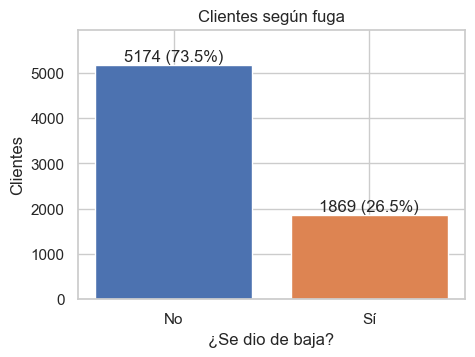

In [10]:
# Gráfico 1: distribución de la variable objetivo
conteo = df_limpio["fuga"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 80, f"{v} ({v / conteo.sum():.1%})", ha="center")
ax.set_title("Clientes según fuga")
ax.set_xlabel("¿Se dio de baja?")
ax.set_ylabel("Clientes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.show()

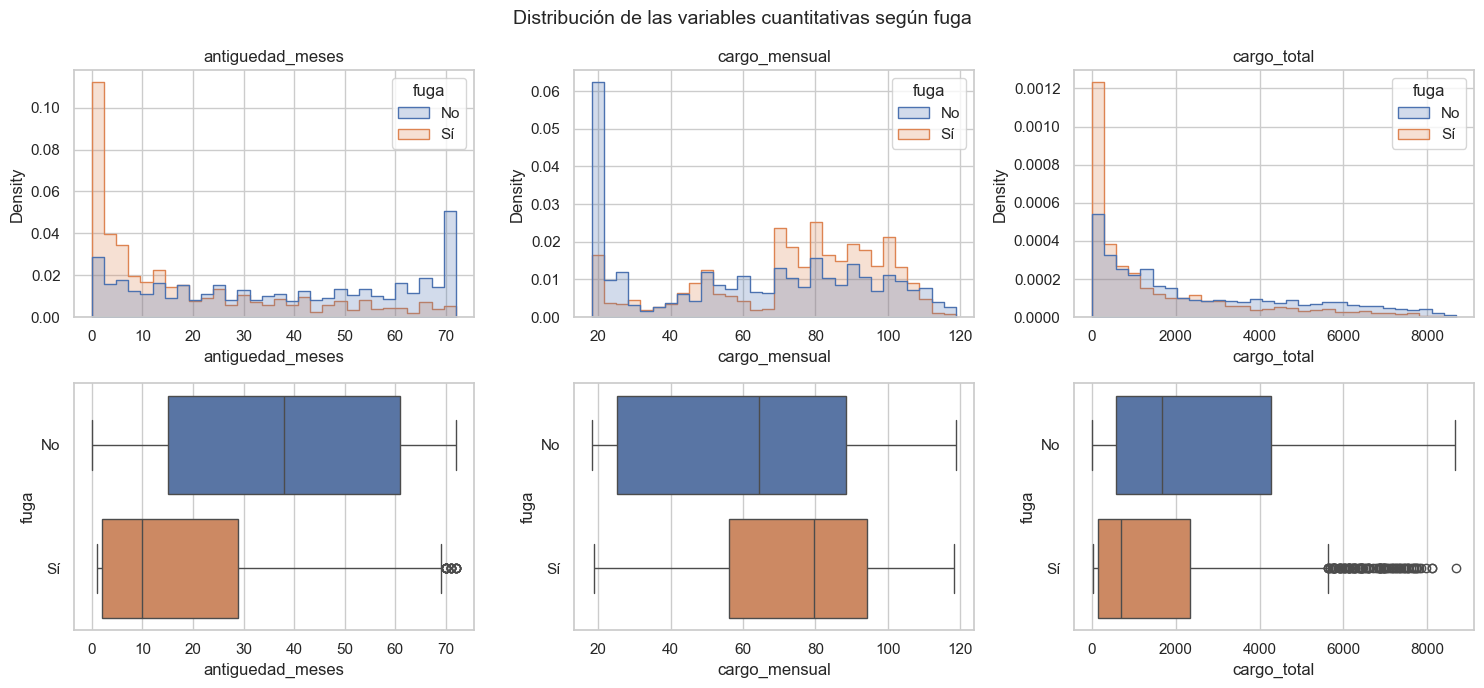

In [11]:
# Gráfico 2: variables cuantitativas según fuga
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, var in enumerate(NUMERICAS):
    sns.histplot(data=df_limpio, x=var, hue="fuga", palette=COLORES, bins=30, ax=ax[0, j], element="step", stat="density", common_norm=False)
    sns.boxplot(data=df_limpio, x=var, y="fuga", hue="fuga", palette=COLORES, ax=ax[1, j], legend=False)
    ax[0, j].set_title(var)
fig.suptitle("Distribución de las variables cuantitativas según fuga", fontsize=14)
plt.tight_layout()
plt.show()

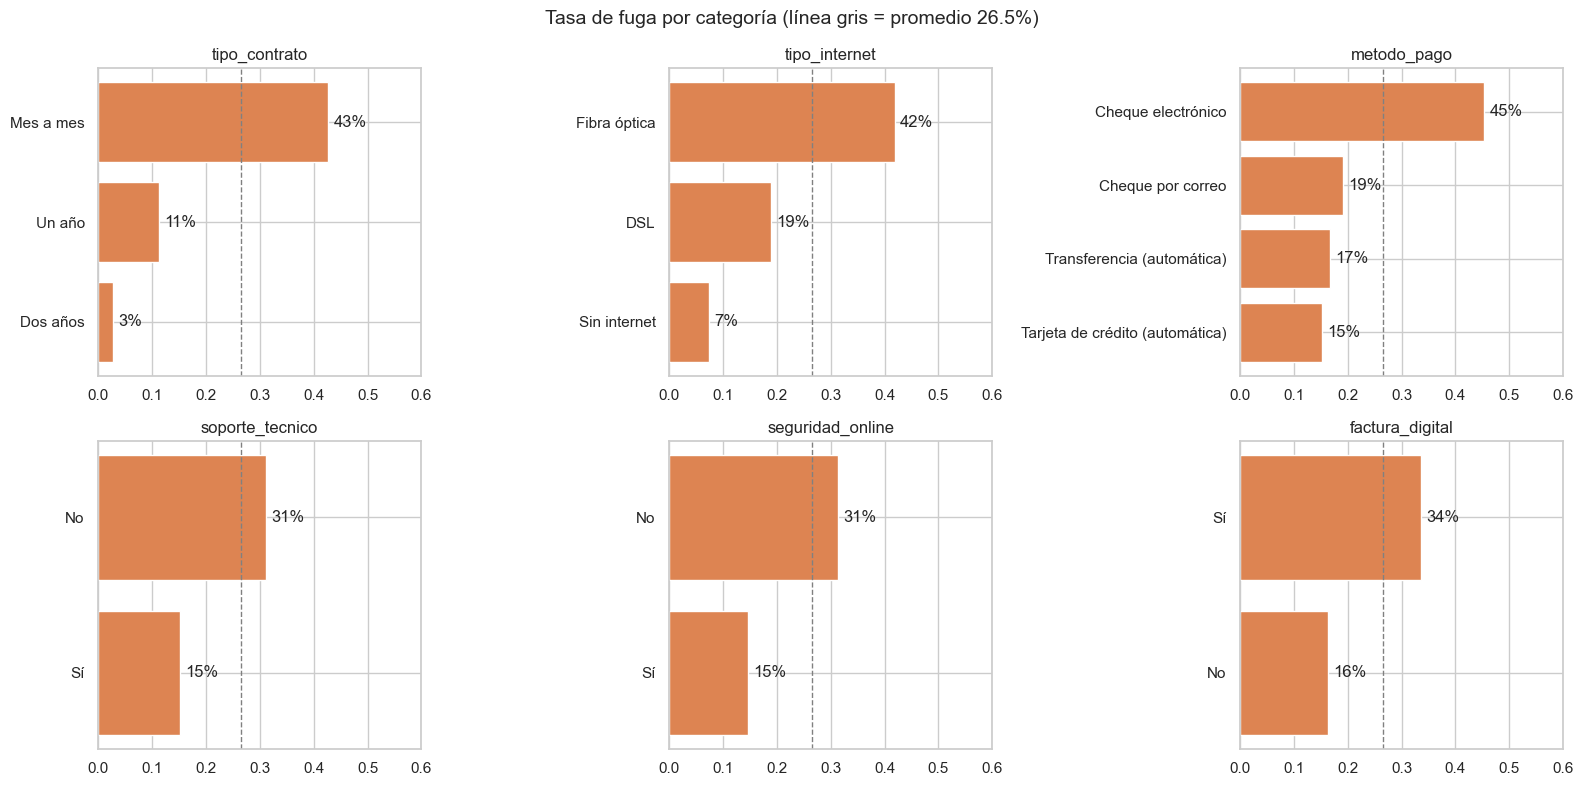

In [12]:
# Gráfico 3: tasa de fuga por categoría
CATEGORICAS_EDA = ["tipo_contrato", "tipo_internet", "metodo_pago", "soporte_tecnico", "seguridad_online", "factura_digital"]
tasa_global = (df_limpio["fuga"] == "Sí").mean()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, var in zip(axes.flat, CATEGORICAS_EDA):
    tasa = df_limpio.groupby(var)["fuga"].apply(lambda s: (s == "Sí").mean()).sort_values()
    ax.barh(tasa.index, tasa.values, color="#DD8452")
    ax.axvline(tasa_global, color="gray", ls="--", lw=1)
    for i, v in enumerate(tasa.values):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center")
    ax.set_title(var)
    ax.set_xlim(0, 0.6)
fig.suptitle(f"Tasa de fuga por categoría (línea gris = promedio {tasa_global:.1%})", fontsize=14)
plt.tight_layout()
plt.show()

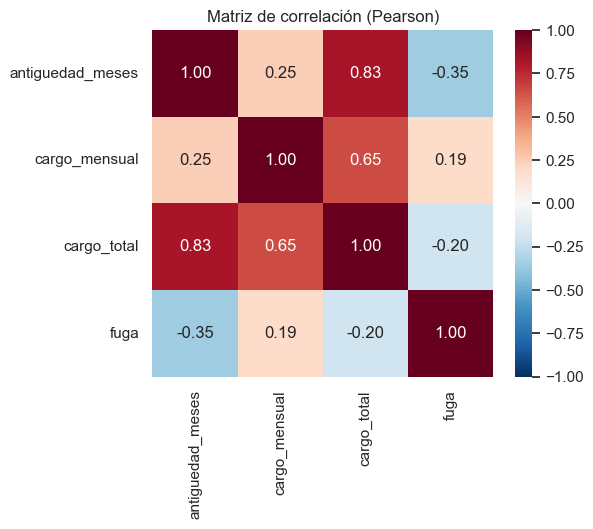

In [13]:
# Gráfico 4: correlación entre variables cuantitativas (y con la fuga)
corr = df_limpio[NUMERICAS].assign(fuga=(df_limpio["fuga"] == "Sí").astype(int)).corr()
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Pearson)")
plt.show()

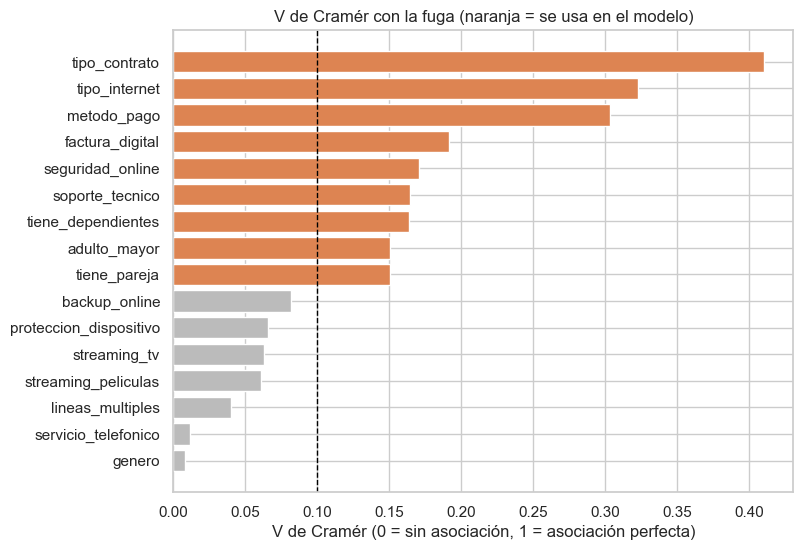

,tipo_contrato,tipo_internet,metodo_pago,factura_digital,seguridad_online,soporte_tecnico,tiene_dependientes,adulto_mayor,tiene_pareja,backup_online,proteccion_dispositivo,streaming_tv,streaming_peliculas,lineas_multiples,servicio_telefonico,genero
V de Cramér,0.41,0.322,0.303,0.191,0.171,0.164,0.164,0.15,0.15,0.082,0.066,0.063,0.061,0.04,0.011,0.008


In [14]:
# Gráfico 5: fuerza de asociación de cada variable con la fuga
def v_de_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

CATEGORICAS = [c for c in df_limpio.columns if df_limpio[c].dtype == object and c not in ("id_cliente", "fuga")]
asociacion = pd.Series({c: v_de_cramer(df_limpio[c], df_limpio["fuga"]) for c in CATEGORICAS}).sort_values()

UMBRAL_V = 0.10
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(asociacion.index, asociacion.values, color=["#DD8452" if v >= UMBRAL_V else "#BBBBBB" for v in asociacion.values])
ax.axvline(UMBRAL_V, color="black", ls="--", lw=1)
ax.set_title("V de Cramér con la fuga (naranja = se usa en el modelo)")
ax.set_xlabel("V de Cramér (0 = sin asociación, 1 = asociación perfecta)")
plt.show()
asociacion.sort_values(ascending=False).round(3).to_frame("V de Cramér").T

#### Conclusiones del EDA

| Hallazgo | Evidencia | Lectura de negocio |
|---|---|---|
| El **contrato mes a mes** es el mayor factor de riesgo | 43 % de fuga vs. 11 % (1 año) y 3 % (2 años); V = 0,41 | Pasar clientes a contratos anuales es la palanca más fuerte |
| Los **clientes nuevos** se van más | Antigüedad mediana: 10 meses (fuga) vs. 38 meses (no fuga) | Los primeros 12 meses son críticos: hace falta un buen *onboarding* |
| **Fibra óptica** tiene más fuga | 42 % vs. 19 % en DSL | Posible problema de precio o calidad del servicio de fibra |
| **Cheque electrónico** es el método más riesgoso | 45 % vs. ~16 % en pagos automáticos | Incentivar el débito automático |
| Sin **soporte técnico** ni **seguridad online** | 31 % de fuga vs. 15 % con el servicio | Los servicios de valor agregado fidelizan |
| **Factura digital** y **adulto mayor** | 34 % vs. 16 % (factura digital) y 42 % vs. 24 % (adulto mayor) | Perfiles a vigilar; la factura digital suele ir junto con el cheque electrónico |
| Sin pareja ni dependientes | 33 % vs. 20 % (pareja) y 31 % vs. 15 % (dependientes) | Los hogares con familia son más estables |
| Cargo mensual alto → más fuga | Media 74 USD (fuga) vs. 61 USD (no fuga) | Sensibilidad al precio |
| `cargo_total` es redundante | r = 0,83 con antigüedad | Se excluye |
| Género y telefonía no influyen | V ≈ 0,01 | Se excluyen |

#### Selección de variables
El gráfico de V de Cramér muestra un **corte natural**: 9 variables tienen V ≥ 0,15 y el resto tiene V ≤ 0,08. Se toman esas 9 categóricas (umbral 0,10) más las dos cuantitativas no redundantes. Quedan **11 variables explicativas**: `antiguedad_meses`, `cargo_mensual`, `tipo_contrato`, `tipo_internet`, `metodo_pago`, `factura_digital`, `seguridad_online`, `soporte_tecnico`, `tiene_dependientes`, `adulto_mayor` y `tiene_pareja`. Se descartan 9 variables (género, telefonía, streaming, backup, etc.). Menos variables vuelven al modelo **más simple de explicar** (RNF7) y al simulador de la app **más fácil de usar** (RF4).

In [15]:
# Dataset final para el modelado
VARS_NUMERICAS = ["antiguedad_meses", "cargo_mensual"]
VARS_CATEGORICAS = ["tipo_contrato", "tipo_internet", "metodo_pago", "factura_digital", "seguridad_online",
                    "soporte_tecnico", "tiene_dependientes", "adulto_mayor", "tiene_pareja"]
VARIABLES_MODELO = VARS_NUMERICAS + VARS_CATEGORICAS

df_modelo = df_limpio[["id_cliente"] + VARIABLES_MODELO].copy()
df_modelo["fuga"] = (df_limpio["fuga"] == "Sí").astype(int)
print("Dataset final:", df_modelo.shape)
df_modelo.head()

Dataset final: (7043, 13)


,id_cliente,antiguedad_meses,cargo_mensual,tipo_contrato,tipo_internet,metodo_pago,factura_digital,seguridad_online,soporte_tecnico,tiene_dependientes,adulto_mayor,tiene_pareja,fuga
0,7590-VHVEG,1,29.85,Mes a mes,DSL,Cheque electrónico,Sí,No,No,No,No,Sí,0
1,5575-GNVDE,34,56.95,Un año,DSL,Cheque por correo,No,Sí,No,No,No,No,0
2,3668-QPYBK,2,53.85,Mes a mes,DSL,Cheque por correo,Sí,Sí,No,No,No,No,1
3,7795-CFOCW,45,42.30,Un año,DSL,Transferencia (automática),No,Sí,Sí,No,No,No,0
4,9237-HQITU,2,70.70,Mes a mes,Fibra óptica,Cheque electrónico,Sí,No,No,No,No,No,1


## Fase #4: Modelado / Modeling
En esta fase, se seleccionan y aplican diversas técnicas de modelado y se calibran sus parámetros a valores óptimos. Normalmente, hay varias técnicas para el mismo tipo de problema de minería de datos. Algunas técnicas tienen requisitos específicos en cuanto a la forma de los datos. Por lo tanto, a menudo es necesario volver a la fase de preparación dedatos.
* Seleccioná una variable objetivo que te permita cumplir el objetivo del estudio.
* Investigá un algoritmo de Ciencia de Datos que pueda ayudarte a predecir el comportamiento de esa variable. Explicá brevemente por qué te sería útil.
* Implementa el algoritmo.

### Desarrollo — Fase #4

#### 1. Variable objetivo
**`fuga`** (1 = el cliente se dio de baja, 0 = sigue activo). Predecirla responde directamente al objetivo general: saber **quién** se va a ir antes de que pase.

#### 2. Algoritmo elegido: Regresión Logística
La regresión logística estima la **probabilidad** de que un cliente se vaya. Combina las variables en un puntaje lineal y lo transforma con la función sigmoide en un valor entre 0 y 1:

$$P(\text{fuga}=1) = \frac{1}{1 + e^{-(b_0 + b_1x_1 + \dots + b_nx_n)}}$$

**¿Por qué nos sirve?**
- Da una **probabilidad**, no solo un Sí/No → permite **ordenar a los clientes por riesgo** (RF1, RF2, RF3).
- Cada coeficiente dice **cuánto sube o baja el riesgo** cada variable → se le puede explicar al área comercial (RNF7) y genera las "acciones sugeridas" de la app (RF5).
- Es liviana: el modelo entrenado es una fórmula que corre **directamente en el navegador**, sin servidor (RNF2, RNF3).

Para comparar se entrena también un **Árbol de Decisión** (reglas *si… entonces…*, muy fáciles de leer) y un modelo de referencia (*baseline*) que siempre predice "no se va".

| Modelo | Ventajas | Desventajas |
|---|---|---|
| Baseline (siempre "No") | Sirve de piso: cualquier modelo útil tiene que superarlo | No detecta ninguna fuga |
| **Regresión Logística** | Probabilidades, interpretable, rápida, fácil de desplegar | Supone relaciones lineales en el puntaje |
| Árbol de Decisión | Reglas visuales, capta interacciones | Inestable, tiende al sobreajuste si es profundo |

**Decisiones de diseño:**
- **Partición 80/20 estratificada** (mantiene el 26,5 % de fuga en ambas partes) con semilla fija para reproducibilidad.
- `class_weight="balanced"`: el modelo da más peso a los clientes que se van, porque son minoría y son los que nos interesa detectar.
- Variables categóricas en **one-hot** (una columna 0/1 por categoría) y cuantitativas **estandarizadas**. El escalador se ajusta **solo con los datos de entrenamiento**, para no filtrar información del test.
- **Validación cruzada de 5 particiones** para elegir la profundidad del árbol (probando varias con un `for`) y verificar la estabilidad.

In [16]:
#Acá debés cargar las librerías con las que trabajarás en esta fase
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier

SEMILLA = 42

In [17]:
#Acá debés poder implementar un modelo y entrenarlo
X = df_modelo[VARIABLES_MODELO]
y = df_modelo["fuga"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train)} clientes | Prueba: {len(X_test)} clientes | % fuga en ambos: {y_train.mean():.1%} / {y_test.mean():.1%}")

# Categoría de referencia (la primera de cada lista): el perfil "base" contra el que se comparan los coeficientes
ORDEN_CATEGORIAS = {
    "tipo_contrato": ["Mes a mes", "Un año", "Dos años"],
    "tipo_internet": ["DSL", "Fibra óptica", "Sin internet"],
    "metodo_pago": ["Transferencia (automática)", "Tarjeta de crédito (automática)", "Cheque electrónico", "Cheque por correo"],
    **{v: ["No", "Sí"] for v in ["factura_digital", "seguridad_online", "soporte_tecnico", "tiene_dependientes", "adulto_mayor", "tiene_pareja"]},
}
PROFUNDIDADES = [2, 3, 4, 5, 6, 7, 8, 9, 10]                                     # profundidades del árbol a probar
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)            # validación cruzada de 5 particiones

Entrenamiento: 5634 clientes | Prueba: 1409 clientes | % fuga en ambos: 26.5% / 26.5%


In [18]:
# >>> OPCIÓN A: pasos sueltos (activa) — celda 1 de 3 <<<
# 1) One-hot: una columna 0/1 por cada categoría, salvo la de referencia (la primera de cada lista)
def codificar(datos):
    codificado = datos[VARS_NUMERICAS].copy()
    for var in VARS_CATEGORICAS:
        for categoria in ORDEN_CATEGORIAS[var][1:]:
            codificado[f"{var}_{categoria}"] = (datos[var] == categoria).astype(int)
    return codificado

X_train_modelo = codificar(X_train)
X_test_modelo = codificar(X_test)

# 2) Estandarizar las numéricas (media 0, desvío 1). El escalador se ajusta SOLO con entrenamiento
escalador = StandardScaler().fit(X_train_modelo[VARS_NUMERICAS])
X_train_modelo[VARS_NUMERICAS] = escalador.transform(X_train_modelo[VARS_NUMERICAS])
X_test_modelo[VARS_NUMERICAS] = escalador.transform(X_test_modelo[VARS_NUMERICAS])

nombres = X_train_modelo.columns
print(f"Variables después de codificar: {len(nombres)}")
X_train_modelo.head()

Variables después de codificar: 15


,antiguedad_meses,cargo_mensual,tipo_contrato_Un año,tipo_contrato_Dos años,tipo_internet_Fibra óptica,tipo_internet_Sin internet,metodo_pago_Tarjeta de crédito (automática),metodo_pago_Cheque electrónico,metodo_pago_Cheque por correo,factura_digital_Sí,seguridad_online_Sí,soporte_tecnico_Sí,tiene_dependientes_Sí,adulto_mayor_Sí,tiene_pareja_Sí
3738,0.102371,-0.521976,0,0,0,0,0,1,0,0,0,0,0,0,0
3151,-0.711743,0.337478,0,0,1,0,0,0,1,0,1,0,1,0,1
4860,-0.793155,-0.809013,0,1,0,0,0,0,1,0,1,1,1,0,1
3867,-0.263980,0.284384,0,1,0,0,1,0,0,1,0,0,0,0,1
3810,-1.281624,-0.676279,0,0,0,0,0,1,0,0,0,0,1,0,1


In [19]:
# >>> OPCIÓN A: pasos sueltos (activa) — celda 2 de 3 <<<
# 3) Modelo principal: Regresión Logística
modelo_lr = LogisticRegression(class_weight="balanced", max_iter=1000)
modelo_lr.fit(X_train_modelo, y_train)
clf_lr = modelo_lr  # nombre que usan las celdas siguientes

# 4) Baseline: siempre predice la clase más frecuente ("no se va")
modelo_base = DummyClassifier(strategy="most_frequent").fit(X_train_modelo, y_train)
print("Regresión logística y baseline entrenados.")

Regresión logística y baseline entrenados.


In [20]:
# >>> OPCIÓN A: pasos sueltos (activa) — celda 3 de 3 <<<
# 5) Árbol de Decisión: probamos varias profundidades y nos quedamos con la mejor.
#    Se mide con validación cruzada sobre entrenamiento (el test no se toca).
#    min_samples_leaf=50: cada hoja debe tener al menos 50 clientes, para evitar sobreajuste.
scoring_arboles = []
for profundidad in PROFUNDIDADES:
    arbol_prueba = DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=50, class_weight="balanced", random_state=SEMILLA)
    auc = cross_val_score(arbol_prueba, X_train_modelo, y_train, cv=cv, scoring="roc_auc").mean()
    scoring_arboles.append(auc)
    print(f"Árbol de profundidad {profundidad:2d}: ROC-AUC promedio = {auc:.4f}")

mejor_profundidad = PROFUNDIDADES[int(np.argmax(scoring_arboles))]
print(f"\nEl mejor árbol es el de profundidad {mejor_profundidad}, con ROC-AUC = {max(scoring_arboles):.4f}")

modelo_arbol = DecisionTreeClassifier(max_depth=mejor_profundidad, min_samples_leaf=50, class_weight="balanced", random_state=SEMILLA)
modelo_arbol.fit(X_train_modelo, y_train)
arbol = modelo_arbol  # nombre que usan las celdas siguientes

Árbol de profundidad  2: ROC-AUC promedio = 0.7410
Árbol de profundidad  3: ROC-AUC promedio = 0.7972


Árbol de profundidad  4: ROC-AUC promedio = 0.8209


Árbol de profundidad  5: ROC-AUC promedio = 0.8283


Árbol de profundidad  6: ROC-AUC promedio = 0.8315


Árbol de profundidad  7: ROC-AUC promedio = 0.8328
Árbol de profundidad  8: ROC-AUC promedio = 0.8337


Árbol de profundidad  9: ROC-AUC promedio = 0.8334


Árbol de profundidad 10: ROC-AUC promedio = 0.8334

El mejor árbol es el de profundidad 8, con ROC-AUC = 0.8337


In [21]:
# >>> OPCIÓN B: Pipeline + GridSearchCV (comentada) <<<
# Hace lo mismo que las 3 celdas de la Opción A en menos líneas y da los mismos resultados.
# Para usarla: borrar las 3 celdas de la Opción A y descomentar esta celda (Ctrl + /).
#
# from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import OneHotEncoder
# from sklearn.pipeline import Pipeline
# from sklearn.model_selection import GridSearchCV
#
# # Preprocesamiento: estandarizar numéricas + one-hot de categóricas (se ajusta solo con entrenamiento)
# preprocesamiento = ColumnTransformer([
#     ("num", StandardScaler(), VARS_NUMERICAS),
#     ("cat", OneHotEncoder(categories=[ORDEN_CATEGORIAS[c] for c in VARS_CATEGORICAS], drop="first"), VARS_CATEGORICAS),
# ], verbose_feature_names_out=False)
#
# # Modelo principal: Regresión Logística
# modelo_lr = Pipeline([("prep", preprocesamiento), ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])
# modelo_lr.fit(X_train, y_train)
#
# # Árbol de Decisión: GridSearchCV prueba todas las profundidades con validación cruzada
# busqueda_arbol = GridSearchCV(
#     Pipeline([("prep", preprocesamiento), ("clf", DecisionTreeClassifier(min_samples_leaf=50, class_weight="balanced", random_state=SEMILLA))]),
#     param_grid={"clf__max_depth": PROFUNDIDADES}, scoring="roc_auc", cv=cv,
# )
# busqueda_arbol.fit(X_train, y_train)
# modelo_arbol = busqueda_arbol.best_estimator_
# print("Mejor árbol:", busqueda_arbol.best_params_, f"ROC-AUC = {busqueda_arbol.best_score_:.4f}")
#
# # Baseline
# modelo_base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
#
# # Nombres que usan las celdas siguientes (los mismos que define la Opción A)
# X_train_modelo, X_test_modelo = X_train, X_test   # el pipeline recibe los datos sin codificar
# clf_lr = modelo_lr.named_steps["clf"]
# escalador = modelo_lr.named_steps["prep"].named_transformers_["num"]
# arbol = modelo_arbol.named_steps["clf"]
# nombres = modelo_lr.named_steps["prep"].get_feature_names_out()

In [22]:
# Validación cruzada (5 particiones) sobre entrenamiento: ¿los resultados son estables?
filas = []
for nombre, modelo in [("Regresión Logística", modelo_lr), ("Árbol de Decisión", modelo_arbol)]:
    r = cross_validate(modelo, X_train_modelo, y_train, cv=cv, scoring=["recall", "precision", "roc_auc"])
    filas.append({"Modelo": nombre,
                  "Recall": f"{r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
                  "Precision": f"{r['test_precision'].mean():.3f} ± {r['test_precision'].std():.3f}",
                  "ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}"})
pd.DataFrame(filas).set_index("Modelo")

,Recall,Precision,ROC-AUC
Modelo,,,
Regresión Logística,0.793 ± 0.031,0.516 ± 0.015,0.843 ± 0.012
Árbol de Decisión,0.806 ± 0.010,0.504 ± 0.022,0.834 ± 0.012


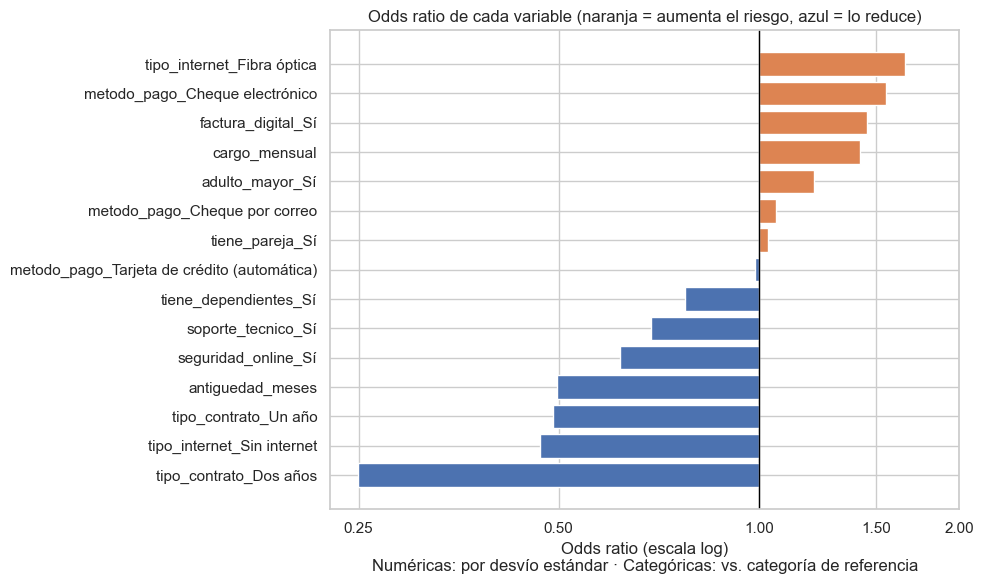

,Odds ratio
tipo_internet_Fibra óptica,1.66
metodo_pago_Cheque electrónico,1.55
factura_digital_Sí,1.45
cargo_mensual,1.42
adulto_mayor_Sí,1.21
metodo_pago_Cheque por correo,1.06
tiene_pareja_Sí,1.03
metodo_pago_Tarjeta de crédito (automática),0.99
tiene_dependientes_Sí,0.77
soporte_tecnico_Sí,0.69


In [23]:
# Interpretación: ¿qué aumenta o reduce el riesgo de fuga? (odds ratio = e^coeficiente)
coeficientes = pd.Series(clf_lr.coef_[0], index=nombres).sort_values()
odds_ratio = np.exp(coeficientes)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(odds_ratio.index, odds_ratio.values - 1, left=1, color=["#4C72B0" if v < 1 else "#DD8452" for v in odds_ratio.values])
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 1.5, 2])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.minorticks_off()
ax.set_title("Odds ratio de cada variable (naranja = aumenta el riesgo, azul = lo reduce)")
ax.set_xlabel("Odds ratio (escala log)" + chr(10) + "Numéricas: por desvío estándar · Categóricas: vs. categoría de referencia")
plt.tight_layout()
plt.show()
odds_ratio.sort_values(ascending=False).round(2).to_frame("Odds ratio")

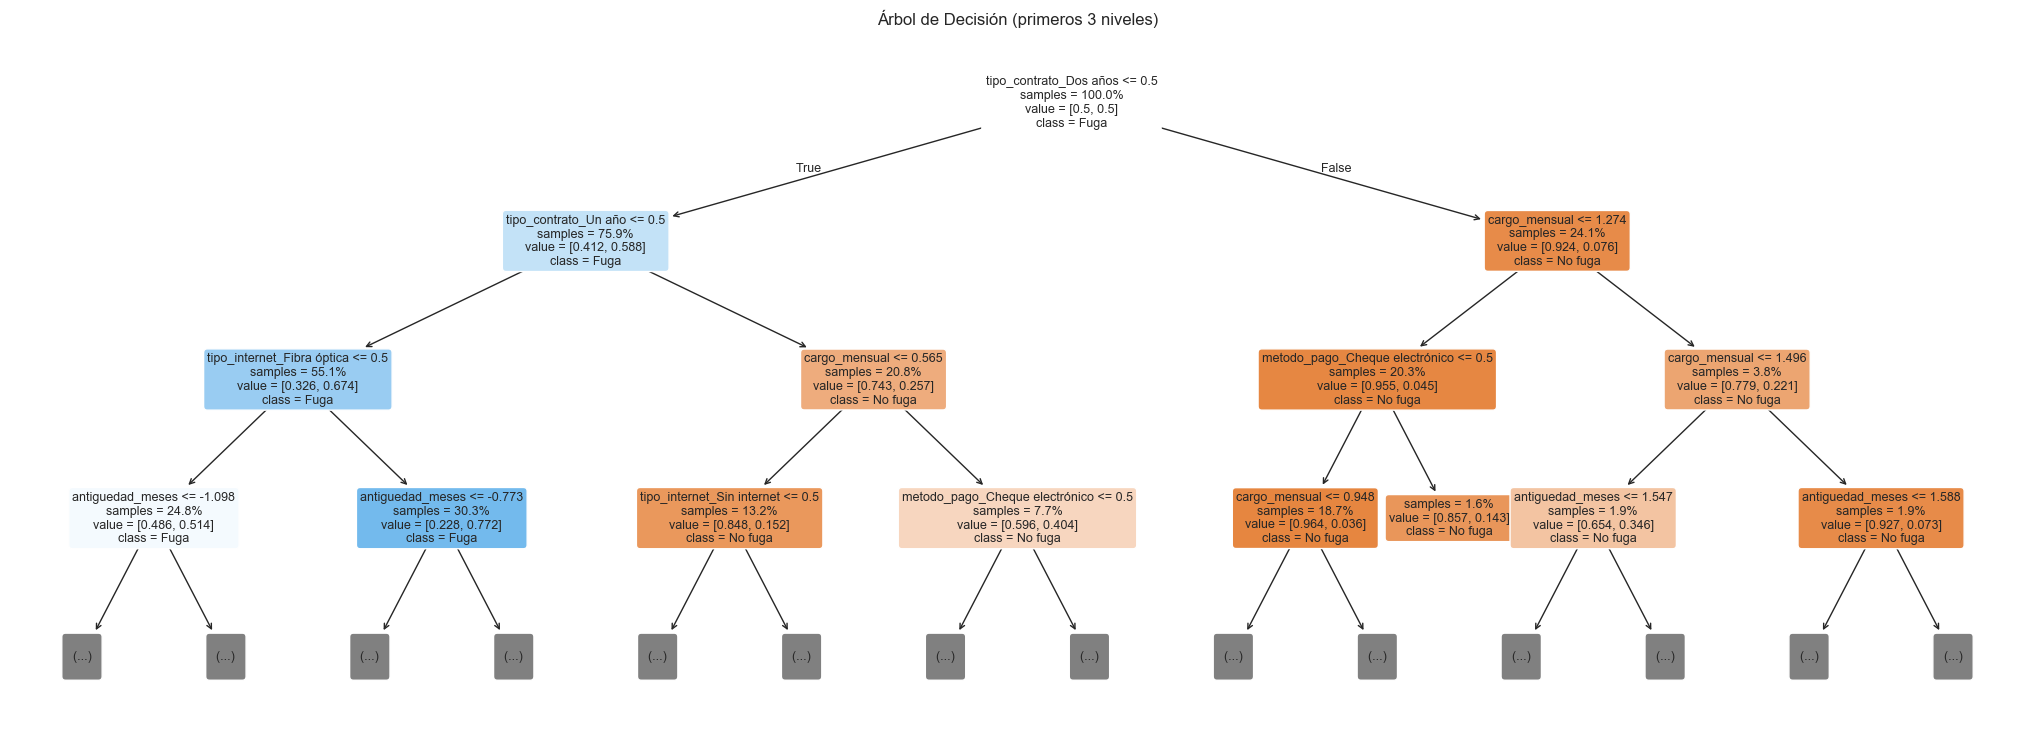

In [24]:
# Visualización del árbol de decisión (primeros 3 niveles)
plt.figure(figsize=(26, 9))
plot_tree(arbol, max_depth=3, feature_names=nombres, class_names=["No fuga", "Fuga"], filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Árbol de Decisión (primeros 3 niveles)")
plt.show()

**Lectura del modelo:**
- **Bajan el riesgo:** contrato de **dos años** (odds × 0,25) o **un año** (× 0,49), mayor **antigüedad** (× 0,50 por cada ~25 meses), **seguridad online** (× 0,62), **soporte técnico** (× 0,69) y tener **dependientes** (× 0,77).
- **Suben el riesgo:** **fibra óptica** (× 1,66), **cheque electrónico** (× 1,55), **factura digital** (× 1,45), **cargo mensual** alto (× 1,42 por cada ~30 USD) y ser **adulto mayor** (× 1,21).
- El árbol llega a las mismas conclusiones: su primera pregunta es el **tipo de contrato** y después el **tipo de internet** (fibra) y el **cargo mensual** (en el gráfico, las variables cuantitativas aparecen estandarizadas). Que dos modelos distintos coincidan **refuerza los hallazgos del EDA**.

## Fase #5: Evaluación / Evaluation
En esta etapa del proyecto, ha construido un modelo (o modelos) que parece tener alta calidad desde una perspectiva de análisis de datos. Antes de proceder a la implementación final del modelo, es importante evaluar más a fondo el modelo y revisar los pasos realizados para construir el modelo y asegurarse de que logra correctamente los objetivos comerciales. Un objetivo clave es determinar si hay algún tema importante del negocio que no se hayaconsiderado lo suficiente. Al final de esta fase, se debe tomar una decisión sobre el uso de los resultados de la minería de datos.
* Investigá sobre las métricas que se utilizan para medir el modelo escogido.
* Evalúa dichas métricas en el modelo implementado e intenta explicarlas.

### Desarrollo — Fase #5

#### 1. Métricas de clasificación
Todas salen de la **matriz de confusión** (positivo = cliente que se va):

| | Predice "se queda" | Predice "se va" |
|---|---|---|
| **Realmente se queda** | VN (verdadero negativo) | FP (falsa alarma) |
| **Realmente se va** | FN (fuga no detectada) | VP (fuga detectada) |

| Métrica | Fórmula | Qué responde en el negocio |
|---|---|---|
| Accuracy | (VP+VN) / Total | ¿Qué % de clientes clasifica bien? **Engaña con clases desbalanceadas** |
| Precision | VP / (VP+FP) | De los clientes que el modelo marca, ¿cuántos se iban de verdad? (eficiencia de la campaña) |
| **Recall (sensibilidad)** | VP / (VP+FN) | De los que se van, ¿cuántos detectamos? **Métrica prioritaria**: una fuga no detectada es un cliente perdido |
| F1-score | 2·P·R / (P+R) | Equilibrio entre precision y recall |
| **ROC-AUC** | Área bajo la curva ROC | Probabilidad de que el modelo le dé más riesgo a un cliente que se va que a uno que se queda (0,5 = azar, 1 = perfecto) |

**¿Por qué priorizamos el recall?** Un FN cuesta un cliente (meses de facturación perdidos). Un FP solo cuesta un llamado o un beneficio. Por eso conviene **aceptar algunas falsas alarmas a cambio de detectar más fugas**.

In [25]:
#Acá debés cargar las librerías con las que trabajarás en esta fase
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, classification_report)

In [26]:
#Acá debés poder validar el modelo, calcular las métricas
#y construir la matriz de confusión
modelos = {"Baseline (siempre 'No')": modelo_base, "Árbol de Decisión": modelo_arbol, "Regresión Logística": modelo_lr}
resultados = {}
for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test_modelo)
    prob = modelo.predict_proba(X_test_modelo)[:, 1]
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    }
tabla_metricas = pd.DataFrame(resultados).T.round(3)
tabla_metricas

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline (siempre 'No'),0.735,0.000,0.000,0.000,0.500
Árbol de Decisión,0.744,0.511,0.813,0.627,0.841
Regresión Logística,0.737,0.503,0.794,0.616,0.836


In [27]:
print(classification_report(y_test, modelo_lr.predict(X_test_modelo), target_names=["No fuga (0)", "Fuga (1)"]))

              precision    recall  f1-score   support

 No fuga (0)       0.91      0.72      0.80      1035
    Fuga (1)       0.50      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



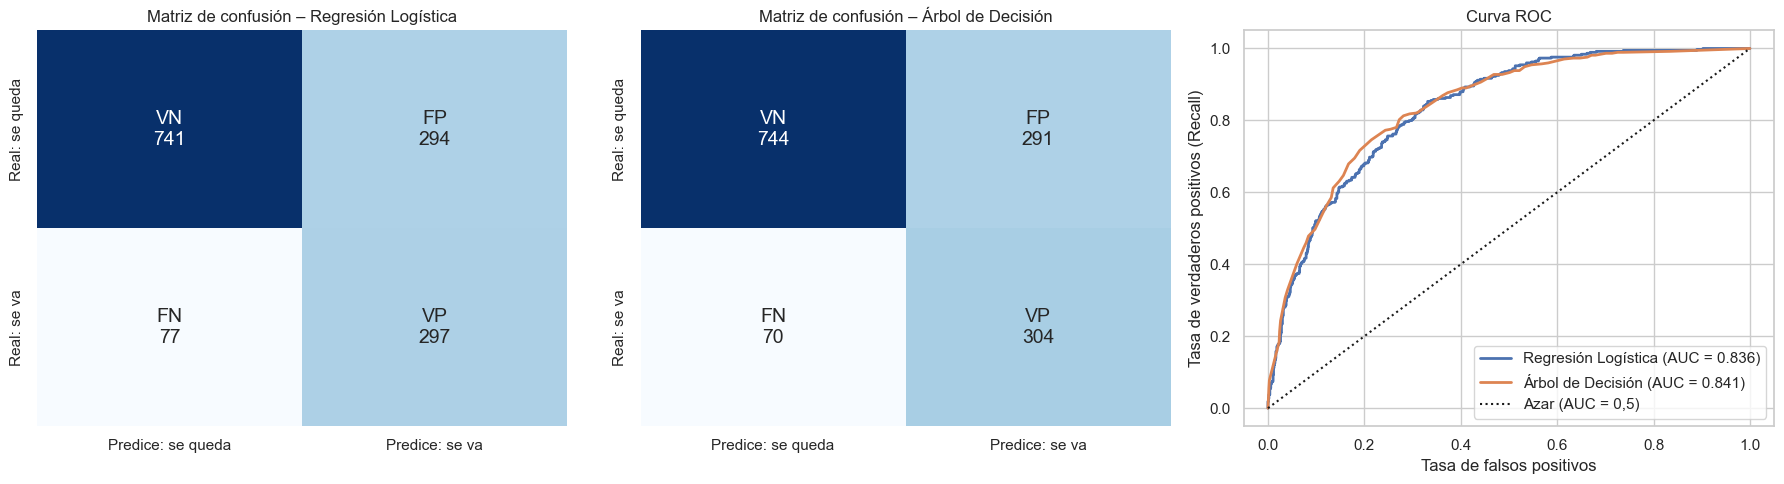

In [28]:
# Matrices de confusión y curva ROC
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, nombre in zip(axes[:2], ["Regresión Logística", "Árbol de Decisión"]):
    cm = confusion_matrix(y_test, modelos[nombre].predict(X_test_modelo))
    etiquetas = np.array([[f"VN\n{cm[0, 0]}", f"FP\n{cm[0, 1]}"], [f"FN\n{cm[1, 0]}", f"VP\n{cm[1, 1]}"]])
    sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["Predice: se queda", "Predice: se va"], yticklabels=["Real: se queda", "Real: se va"])
    ax.set_title(f"Matriz de confusión – {nombre}")

for nombre in ["Regresión Logística", "Árbol de Decisión"]:
    fpr, tpr, _ = roc_curve(y_test, modelos[nombre].predict_proba(X_test_modelo)[:, 1])
    axes[2].plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {resultados[nombre]['ROC-AUC']:.3f})")
axes[2].plot([0, 1], [0, 1], "k:", label="Azar (AUC = 0,5)")
axes[2].set_xlabel("Tasa de falsos positivos")
axes[2].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[2].set_title("Curva ROC")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [29]:
# ¿Qué pasa si movemos el umbral de decisión? (por defecto 0,5)
prob_lr = modelo_lr.predict_proba(X_test_modelo)[:, 1]
filas = []
for umbral in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (prob_lr >= umbral).astype(int)
    filas.append({"Umbral": umbral, "Clientes alertados": int(pred.sum()),
                  "Fugas detectadas (VP)": int(((pred == 1) & (y_test == 1)).sum()),
                  "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred)})
pd.DataFrame(filas).set_index("Umbral").round(3)

,Clientes alertados,Fugas detectadas (VP),Recall,Precision
Umbral,,,,
0.3,816,343,0.917,0.420
0.4,689,322,0.861,0.467
0.5,591,297,0.794,0.503
0.6,490,264,0.706,0.539
0.7,358,214,0.572,0.598


In [30]:
# Impacto económico estimado sobre el conjunto de prueba (SUPUESTOS ILUSTRATIVOS, a validar con Finanzas)
COSTO_ACCION = 50        # USD por cliente contactado (≈ un mes de bonificación + tiempo del agente)
TASA_EXITO = 0.30        # % de las fugas contactadas que se logran retener
MESES_VALOR = 12         # valor de un cliente retenido = 12 meses de su cargo mensual

cargo_test = X_test["cargo_mensual"].values
def impacto(alertados):
    vp = alertados & (y_test.values == 1)
    retenido = TASA_EXITO * (cargo_test[vp] * MESES_VALOR).sum()
    costo = COSTO_ACCION * alertados.sum()
    return {"Clientes contactados": int(alertados.sum()), "Ingreso retenido (USD)": round(retenido),
            "Costo campaña (USD)": round(costo), "Beneficio neto (USD)": round(retenido - costo)}

pred_lr = modelo_lr.predict(X_test_modelo).astype(bool)
rng = np.random.default_rng(SEMILLA)
al_azar = np.zeros(len(y_test), dtype=bool)
al_azar[rng.choice(len(y_test), size=pred_lr.sum(), replace=False)] = True

pd.DataFrame({
    "Sin modelo (no se hace nada)": impacto(np.zeros(len(y_test), dtype=bool)),
    "Contactar a todos": impacto(np.ones(len(y_test), dtype=bool)),
    "Contactar la misma cantidad al azar": impacto(al_azar),
    "Contactar a los que marca el modelo": impacto(pred_lr),
}).T

,Clientes contactados,Ingreso retenido (USD),Costo campaña (USD),Beneficio neto (USD)
Sin modelo (no se hace nada),0,0,0,0
Contactar a todos,1409,97974,70450,27524
Contactar la misma cantidad al azar,591,42915,29550,13365
Contactar a los que marca el modelo,591,81440,29550,51890


#### 2. Interpretación y decisión

- **El baseline confirma la trampa de la accuracy:** sin detectar ninguna fuga, logra 73 % de accuracy. Por eso decidimos con **recall** y **AUC**.
- **La Regresión Logística cumple los objetivos de la Fase 1** (OE4 / RNF4): detecta **8 de cada 10 clientes que se van** (recall = 0,79) con un **ROC-AUC = 0,84**. En la validación cruzada da valores casi iguales (recall 0,79 ± 0,03 y AUC 0,84 ± 0,01), así que el resultado es **estable** y no depende de una partición con suerte.
- **Frente al árbol:** los dos modelos **rinden prácticamente igual**. En el test el árbol queda apenas arriba y en la validación cruzada la logística, siempre con diferencias de 1 a 2 puntos, dentro de la variabilidad normal. Con un rendimiento equivalente elegimos la **regresión logística** porque es **más fácil de explicar** (cada coeficiente se traduce en una acción comercial), es **más estable** frente a cambios en los datos y se **despliega como una simple fórmula** en el navegador. El árbol necesita 8 niveles para rendir igual y deja de ser fácil de leer.
- **Costo de las falsas alarmas:** la precision es de ≈ 0,50 (1 de cada 2 alertas es una fuga real). Es aceptable porque una alerta falsa cuesta un llamado, mientras que una fuga no detectada cuesta un cliente. Si el equipo tiene poca capacidad, se puede **subir el umbral** (tabla de umbrales) y priorizar los riesgos más altos.
- **Impacto en el negocio (con supuestos):** contactar solo a los clientes que marca el modelo da **casi el doble de beneficio neto que contactar a todos** y casi **4 veces más que contactar a la misma cantidad al azar**, porque se recupera el 83 % del ingreso con el 42 % de los contactos. Ojo: si la acción de retención fuera muy barata (≈ USD 20), contactar a todos daría un resultado parecido. El modelo aporta más **cuanto más cara es la acción o más chico es el equipo de retención**.
- **Temas de negocio a considerar:** (1) faltan datos de reclamos y satisfacción, que podrían mejorar el modelo; (2) las probabilidades están "infladas" por el balanceo de clases, por eso se leen como **puntaje de riesgo** para ordenar y no como probabilidad exacta; (3) hay que medir el resultado real de las campañas.

**Decisión:** se aprueba la **Regresión Logística** para su despliegue en la herramienta *Monitor de Fuga* (Fase 6).

## Fase #6: Despliegue (Deployment)
Por lo general, la creación del modelo no es el final del proyecto. Incluso si el propósito delmodelo es aumentar el conocimiento de los datos, el conocimiento adquirido deberá organizarse y presentarse de manera que el cliente pueda utilizarlo. A menudo implica laaplicación de modelos "en vivo" dentro de los procesos de toma de decisiones de una organización, por ejemplo, en la personalización en tiempo real de páginas web o la puntuación repetida de bases de datos de marketing. Sin embargo, en función de los requisitos, la fase de implementación puede ser tan sencilla como generar un informe o tan compleja como implementar un proceso de minería de datos repetible en toda la empresa. En muchos casos, es el cliente, no el analista de datos, quien lleva a cabo los pasos de implementación. Sin embargo, incluso si el analista no llevará a cabo el esfuerzo de implementación, es importante que el cliente comprenda de antemano qué acciones deben llevarse a cabo para hacer uso de los modelos creados.
* Definí un plan para mantener la solución actualizada y funcional. Proporcioná actualizaciones de seguridad y soluciona problemas según sea necesario.
* Colocá acá las vistas del software implementado y el link desde dónde se puede acceder para interactuar con el software (puede estar hardcodeado con las soluciones y gráficos que coloquen acá, en esta notebook).

### Desarrollo — Fase #6

#### 1. Plan de mantenimiento, seguridad y resolución de problemas

| Dimensión | Acción | Frecuencia | Disparador / indicador | Responsable |
|---|---|---|---|---|
| Actualización de datos | Nueva foto mensual de clientes y re-cálculo del riesgo de toda la cartera | Mensual | Cierre de mes | Equipo de Datos |
| Monitoreo del modelo | Comparar las predicciones del mes con las bajas reales y recalcular recall y AUC | Mensual | Recall < 0,75 o AUC < 0,80 → re-entrenar | Equipo de Datos |
| Deriva de datos | Comparar tasa de fuga y medias de antigüedad y cargo con las de entrenamiento | Mensual | Variación > 10 % → revisar | Equipo de Datos |
| Re-entrenamiento | Volver a ejecutar esta notebook con datos nuevos; el nuevo modelo reemplaza al anterior solo si lo supera | Trimestral o por alerta | Mejor AUC en prueba | Equipo de Datos |
| Versionado | Notebook, datos y `modelo_churn.json` en un repositorio Git, con una versión por cada modelo publicado | En cada cambio | — | IT |
| Seguridad | La app no muestra datos personales (solo ID anónimo); acceso por HTTPS; se actualizan las librerías (`pip list --outdated`) y se revisan vulnerabilidades | Mensual | Vulnerabilidad crítica → parche en < 48 h | IT |
| Soporte | Canal de consultas para el equipo de retención; registro de errores | Continuo | — | IT |

**Problemas típicos y solución:**

| Problema | Causa probable | Solución |
|---|---|---|
| Error al cargar datos | Cambió una columna o un formato en el origen | Validar el esquema antes de procesar (controles de la Fase 2) |
| Aparece una categoría nueva (p. ej., otro método de pago) | Cambio comercial | Agregarla en `ORDEN_CATEGORIAS` y re-entrenar |
| Baja el recall | Cambió el comportamiento de los clientes | Re-entrenar con datos recientes |
| La app no carga | Fallo del hosting | Volver a publicar `app/index.html` (es un único archivo estático) |

#### 2. Producto de software: *Monitor de Fuga*
Es una aplicación web de una sola página (HTML + JavaScript, sin servidor). La celda siguiente **exporta el modelo entrenado** (coeficientes, escalado y métricas) a `app/modelo_churn.json` y **genera `app/index.html`**. Así, la app usa **exactamente los mismos coeficientes** que el modelo evaluado en la Fase 5: si se re-entrena, se vuelve a ejecutar la celda y se publica de nuevo.

In [31]:
# Exportar el modelo y generar la aplicación web
import json
from datetime import date

prob_test = modelo_lr.predict_proba(X_test_modelo)[:, 1]
cm_lr = confusion_matrix(y_test, modelo_lr.predict(X_test_modelo))

datos_test = df_limpio.loc[X_test.index]
bandeja = pd.DataFrame({
    "id": datos_test["id_cliente"], **{v: X_test[v] for v in VARIABLES_MODELO},
    "score": prob_test.round(4), "real": y_test.values,
}).sort_values("score", ascending=False)

modelo_export = {
    "version": "1.0",
    "fecha_entrenamiento": date.today().isoformat(),
    "umbral": 0.5,
    "intercepto": float(clf_lr.intercept_[0]),
    "coeficientes": {n: float(c) for n, c in zip(nombres, clf_lr.coef_[0])},
    "escalado": {v: {"media": float(m), "desvio": float(s)} for v, m, s in zip(VARS_NUMERICAS, escalador.mean_, escalador.scale_)},
    "categorias": ORDEN_CATEGORIAS,
    "metricas": {k: {m: float(x) for m, x in v.items()} for k, v in resultados.items()},
    "matriz_confusion": cm_lr.tolist(),
    "resumen": {
        "clientes": int(len(df_limpio)),
        "tasa_fuga": float((df_limpio["fuga"] == "Sí").mean()),
        "clientes_test": int(len(y_test)),
        "fuga_por_contrato": df_limpio.groupby("tipo_contrato")["fuga"].apply(lambda s: (s == "Sí").mean()).round(4).to_dict(),
        "fuga_por_internet": df_limpio.groupby("tipo_internet")["fuga"].apply(lambda s: (s == "Sí").mean()).round(4).to_dict(),
        "fuga_por_pago": df_limpio.groupby("metodo_pago")["fuga"].apply(lambda s: (s == "Sí").mean()).round(4).to_dict(),
    },
    "bandeja": bandeja.to_dict(orient="records"),
}

os.makedirs("app", exist_ok=True)
with open("app/modelo_churn.json", "w", encoding="utf-8") as f:
    json.dump(modelo_export, f, ensure_ascii=False)

# La plantilla de la app tiene la marca /*__MODELO__*/ donde se insertan los datos del modelo
if os.path.exists("app/plantilla_app.html"):
    with open("app/plantilla_app.html", encoding="utf-8") as f:
        html = f.read().replace("/*__MODELO__*/null", json.dumps(modelo_export, ensure_ascii=False))
    with open("app/index.html", "w", encoding="utf-8") as f:
        f.write(html)
    print("App generada: app/index.html")

# Control: la fórmula exportada da las mismas probabilidades que scikit-learn
def prob_formula(fila):
    z = modelo_export["intercepto"]
    for v in VARS_NUMERICAS:
        e = modelo_export["escalado"][v]
        z += modelo_export["coeficientes"][v] * (fila[v] - e["media"]) / e["desvio"]
    for v in VARS_CATEGORICAS:
        z += modelo_export["coeficientes"].get(f"{v}_{fila[v]}", 0.0)
    return 1 / (1 + np.exp(-z))

diferencia = np.abs(X_test.apply(prob_formula, axis=1).values - prob_test).max()
print(f"Diferencia máxima entre la fórmula de la app y scikit-learn: {diferencia:.2e}")

App generada: app/index.html
Diferencia máxima entre la fórmula de la app y scikit-learn: 2.22e-16


#### 4. Link de acceso al software

🔗 **https://prompt-sopa.github.io/TP_INGSOFT_Alsop_Gomez_Aubone_Ponce_Serra/app/**

La app está publicada en **GitHub Pages**, junto con la notebook y el dataset, en el repositorio https://github.com/Prompt-Sopa/TP_INGSOFT_Alsop_Gomez_Aubone_Ponce_Serra. Es un único archivo estático (`app/index.html`): no necesita servidor ni base de datos y se ve bien en computadora y en celular. Para actualizarla, se vuelve a ejecutar esta notebook y se sube el nuevo `app/index.html` al repositorio.

#### 3. Vistas del software

**Vista 1 — Tablero.** Indicadores del modelo (clientes analizados, tasa de fuga, recall, AUC), tasa de fuga por contrato, internet y método de pago, factores de riesgo y matriz de confusión. **Cubre RF6.**

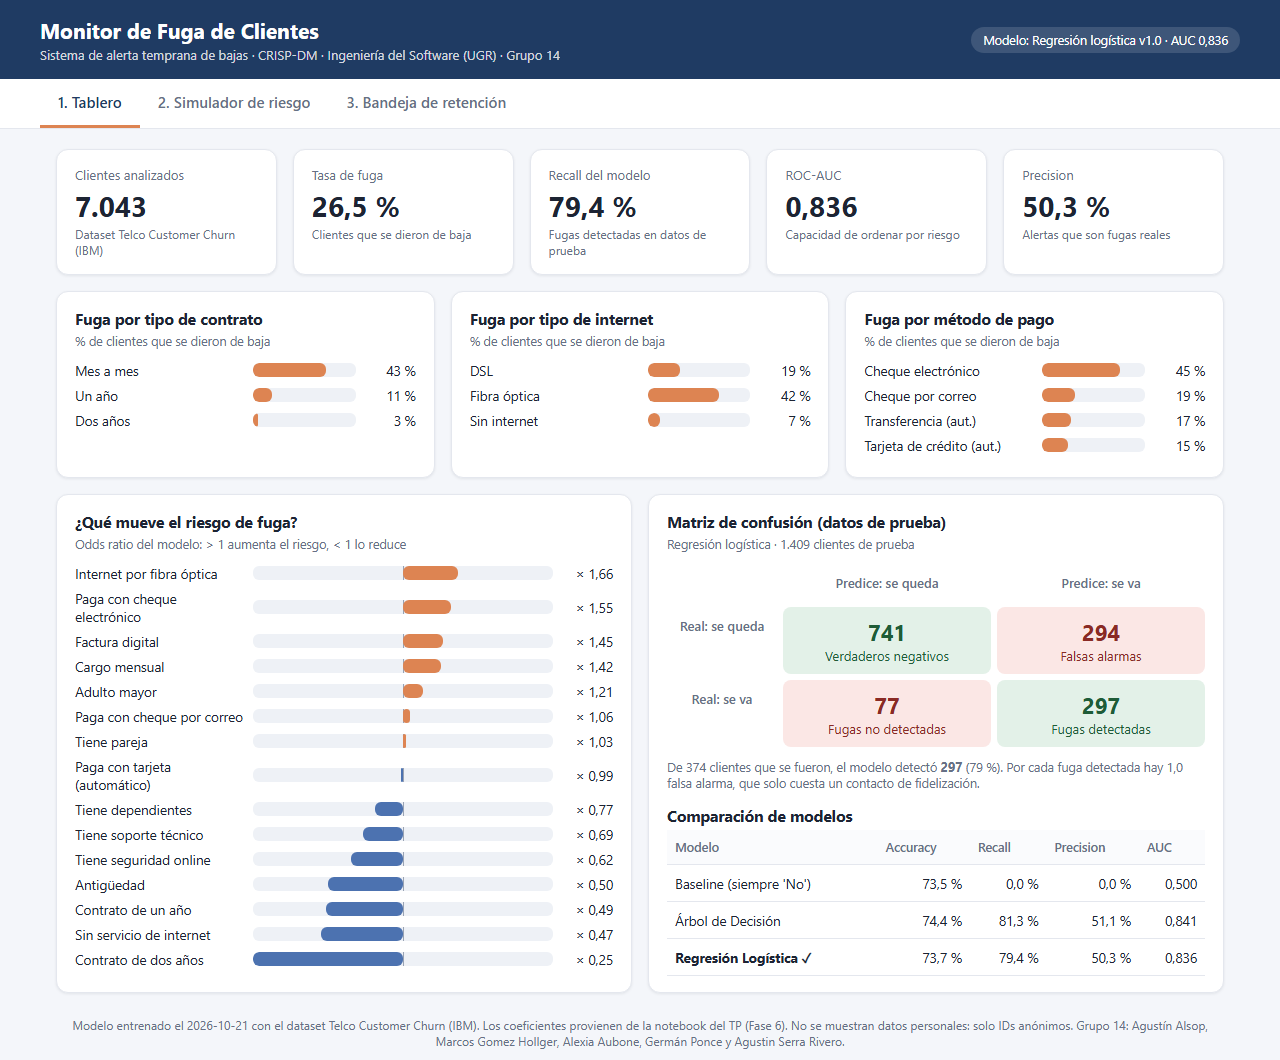

**Vista 2 — Simulador de riesgo.** Se cargan o modifican los datos de un cliente (o un cliente real de la bandeja) y se recalcula al instante su puntaje y nivel de riesgo, con los factores que más pesan y la acción sugerida. **Cubre RF1, RF2, RF4 y RF5.**

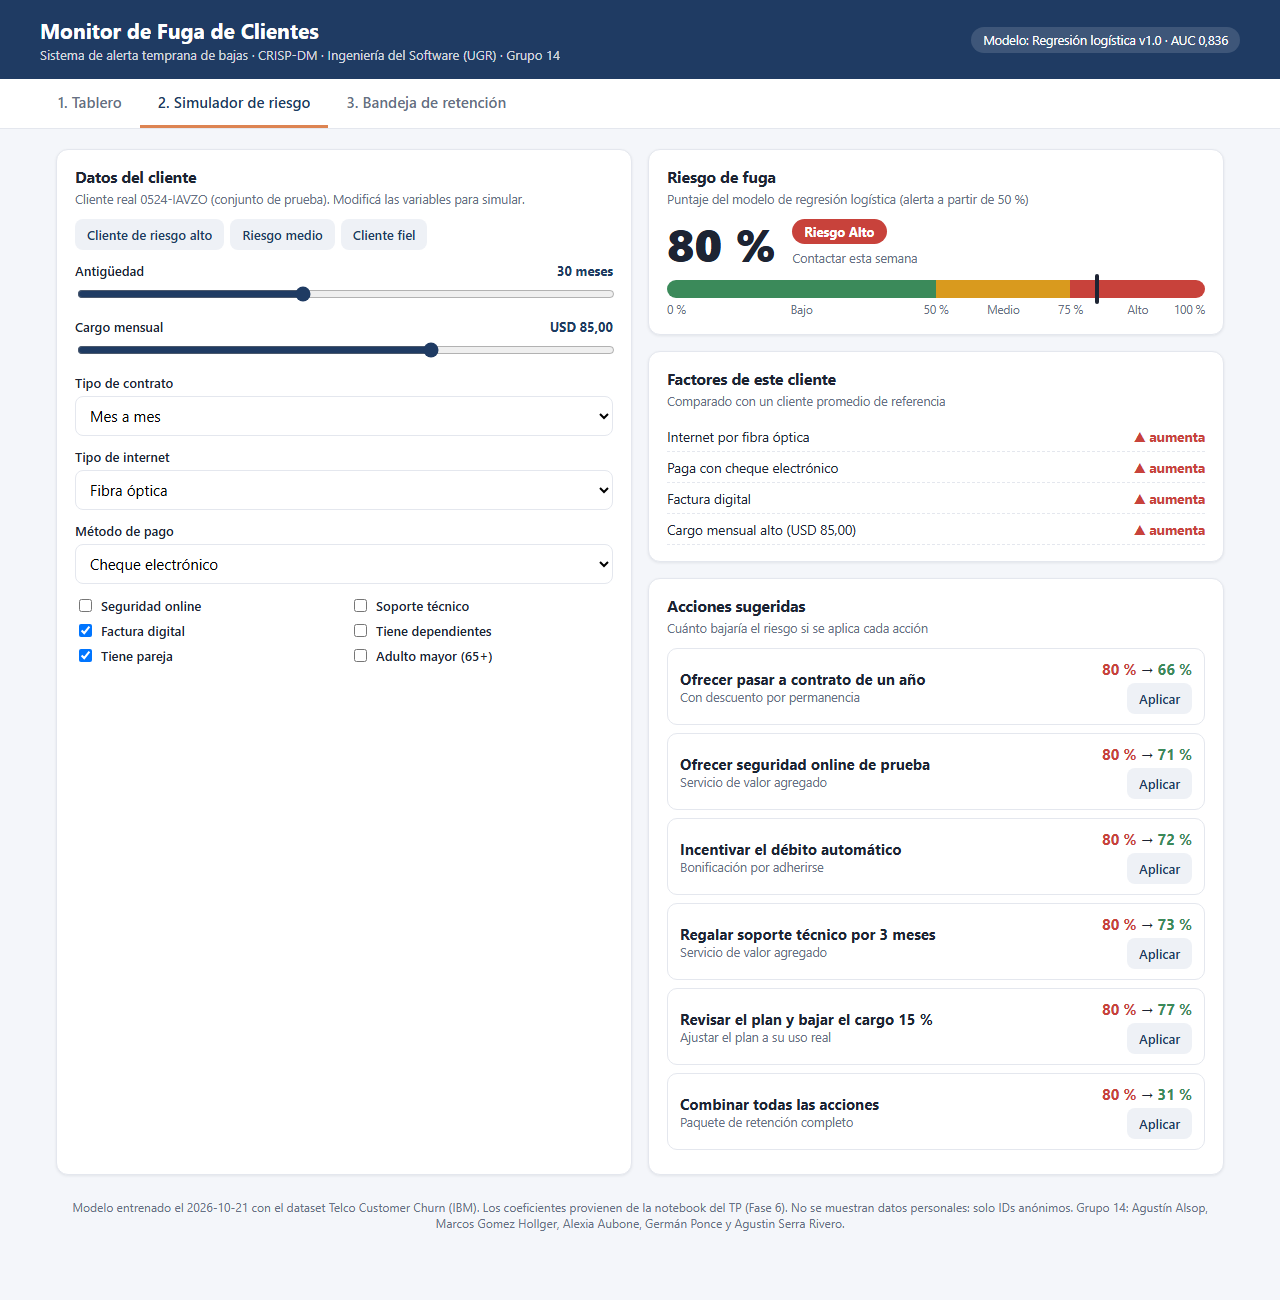

**Vista 3 — Bandeja de retención.** Los clientes del conjunto de prueba ordenados por riesgo, con búsqueda por ID y filtro por nivel. Muestra también si el cliente realmente se fue, para validar el modelo. **Cubre RF3.**

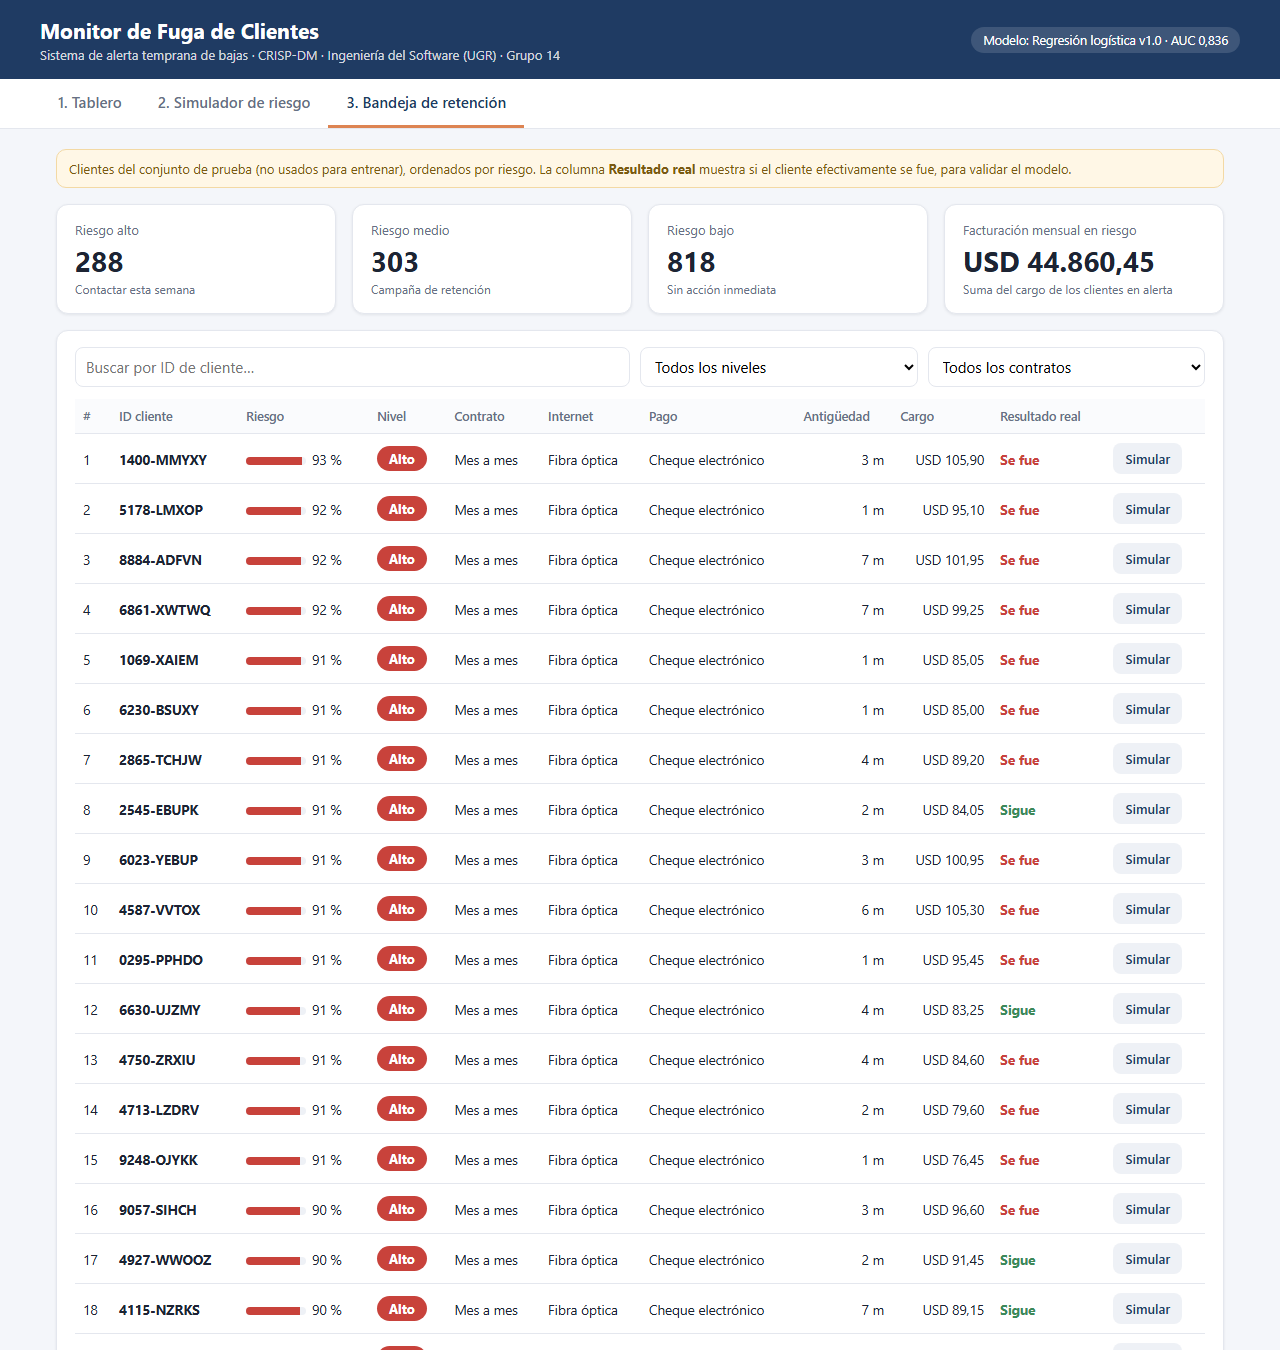

In [32]:
# Vista embebida de la app publicada (funciona en Jupyter y Colab)
from IPython.display import IFrame, display
URL_APP = "https://prompt-sopa.github.io/TP_INGSOFT_Alsop_Gomez_Aubone_Ponce_Serra/app/"
if URL_APP.startswith("http"):
    display(IFrame(URL_APP, width="100%", height=720))
else:
    print("Completar URL_APP con el link de la app publicada.")

### Conclusiones

| Fase | Resultado |
|---|---|
| 1. Negocio | Problema de fuga del 26,5 % de clientes, con objetivos medibles, stakeholders y requerimientos |
| 2. Datos | Dataset real de IBM (7.043 clientes); se detectaron faltantes ocultos, desbalance y redundancias |
| 3. Preparación | Datos limpios y traducidos; EDA con 5 gráficos; 11 variables seleccionadas por V de Cramér |
| 4. Modelado | Regresión logística (elegida) y árbol de decisión, con validación cruzada |
| 5. Evaluación | Recall = 0,79 y AUC = 0,84: **cumple los objetivos**; supera ampliamente al baseline y rinde igual que el árbol, siendo más interpretable |
| 6. Despliegue | App *Monitor de Fuga* con tablero, simulador y bandeja, usando los mismos coeficientes del modelo, más un plan de mantenimiento |

**Principales palancas de retención encontradas:** pasar a los clientes a **contratos anuales**, acompañar los **primeros 12 meses**, promover el **pago automático** y ofrecer **soporte técnico / seguridad online**, sobre todo a los clientes de **fibra óptica**.

### Aclaraciones:
* Buscá la síntesis. No nos interesan las largas explicaciones, sino la capacidad de sintetizar el problema.
* No te extiendas más de lo necesario. Utiliza tablas de resumen, herramientas gráficas. Sé creativo. Este no es un trabajo de conocimiento, es un trabajo de aplicación y comunicación de la estrategia.
* No hay respuestas incorrectas, solo problemas de negocio poco explorados 🙂